# Previsão de calorias de receitas — dataset Epicurious

**Disciplina:** Machine Learning
**Dataset:** [Epicurious - Recipes with Rating and Nutrition](https://www.kaggle.com/datasets/hugodarwood/epirecipes) (Kaggle, `epi_r.csv`)

## 1. Objetivo

Construir um modelo de **regressão** para prever o valor calórico (`calories`) de uma receita a partir de
suas informações nutricionais (`protein`, `fat`, `sodium`) e das *tags* da receita (ingredientes, tipo de prato, dieta etc.).

O desempenho é avaliado por **R²** e, como o modelo completo usa centenas de variáveis, também por **R² ajustado**:

$$R^2_{aj} = 1 - (1 - R^2)\,\frac{n - 1}{n - p - 1}$$

em que $n$ é o número de observações e $p$ o número de variáveis preditoras. O R² ajustado penaliza
variáveis que não agregam informação, então é a métrica correta para comparar modelos com números de variáveis diferentes.

### Roteiro
1. Carga e inspeção dos dados
2. Escolha da variável-alvo
3. Limpeza (duplicatas, valores ausentes, outliers)
4. Análise exploratória
5. Modelagem: regressão linear → regressão linear com todas as tags → seleção de variáveis → modelos reduzidos (regressão linear e Gradient Boosting) → parte extra com modelos maiores
6. Validação cruzada e comparação
7. Diagnóstico dos resíduos e interpretação
8. Conclusões e limitações

In [2]:
import textwrap
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42

# Estilo dos gráficos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelcolor": "#52514e",
    "xtick.color": CINZA, "ytick.color": CINZA, "font.size": 10,
})

## 2. Carga e inspeção dos dados

O arquivo `epi_r.csv` deve estar em `data/`. Se não estiver, a célula abaixo baixa do Kaggle com `kagglehub`.

In [3]:
CAMINHO = Path("data/epi_r.csv")
if not CAMINHO.exists():
    import kagglehub, shutil
    origem = Path(kagglehub.dataset_download("hugodarwood/epirecipes")) / "epi_r.csv"
    CAMINHO.parent.mkdir(exist_ok=True)
    shutil.copy(origem, CAMINHO)

df = pd.read_csv(CAMINHO)
print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
df.iloc[:5, :10]

Linhas: 20,052 | Colunas: 680


,title,rating,calories,protein,fat,sodium,#cakeweek,#wasteless,22-minute meals,3-ingredient recipes
0,"Lentil, Apple, and Turkey Wrap",2.500,426.0,30.0,7.0,559.0,0.0,0.0,0.0,0.0
1,Boudin Blanc Terrine with Red Onion Confit,4.375,403.0,18.0,23.0,1439.0,0.0,0.0,0.0,0.0
2,Potato and Fennel Soup Hodge,3.750,165.0,6.0,7.0,165.0,0.0,0.0,0.0,0.0
3,Mahi-Mahi in Tomato Olive Sauce,5.000,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0
4,Spinach Noodle Casserole,3.125,547.0,20.0,32.0,452.0,0.0,0.0,0.0,0.0


O dataset tem 680 colunas: o título, 5 variáveis numéricas (`rating`, `calories`, `protein`, `fat`, `sodium`)
e 674 *tags* binárias (0/1) que indicam ingredientes, ocasiões, dietas e técnicas de preparo.

### O que são as tags

As tags são **etiquetas que o site Epicurious atribui a cada receita** para classificá-la e facilitar a busca.
No dataset, cada tag virou uma coluna: o valor é **1** se a receita tem aquela etiqueta e **0** se não tem.
Elas descrevem, por exemplo:

| Tipo de tag | Exemplos |
|---|---|
| Ingrediente | `pasta`, `rice`, `chicken`, `tomato` |
| Tipo de prato | `dessert`, `drink`, `salad`, `side` |
| Dieta / restrição | `vegetarian`, `sugar conscious`, `low carb`, `peanut free` |
| Técnica de preparo | `bake`, `grill`, `no-cook` |
| Ocasião / estação | `christmas`, `summer`, `dinner` |
| Origem da receita | `bon appétit`, `gourmet` (revistas) |

A célula abaixo mostra as tags de uma receita como exemplo.

In [4]:
receita = df.iloc[0]
tags_da_receita = [c for c in df.columns[6:] if receita[c] == 1]
print("Receita:", receita["title"])
print("Tags:   ", tags_da_receita)

Receita: Lentil, Apple, and Turkey Wrap 
Tags:    ['apple', 'bean', 'cookie', 'fruit', 'kid-friendly', 'lentil', 'lettuce', 'sandwich', 'tomato', 'vegetable', 'turkey']


In [5]:
NUMERICAS = ["rating", "calories", "protein", "fat", "sodium"]

resumo = df[NUMERICAS].describe(percentiles=[0.5, 0.99]).T
resumo["ausentes"] = df[NUMERICAS].isna().sum()
print(f"Linhas totalmente duplicadas: {df.duplicated().sum():,}")
resumo.round(1)

Linhas totalmente duplicadas: 1,801


,count,mean,std,min,50%,99%,max,ausentes
rating,20052.0,3.7,1.3,0.0,4.4,5.0,5.0,0
calories,15935.0,6323.0,359046.0,0.0,331.0,3238.6,30111218.0,4117
protein,15890.0,100.2,3840.3,0.0,8.0,171.2,236489.0,4162
fat,15869.0,346.9,20456.1,0.0,17.0,207.6,1722763.0,4183
sodium,15933.0,6226.0,333318.2,0.0,294.0,5676.6,27675110.0,4119


Três problemas ficam claros nessa tabela:

- **Valores ausentes:** cerca de 20% das receitas não têm informação nutricional.
- **Duplicatas:** há receitas repetidas. Se uma cópia cair no treino e outra no teste, o modelo "vê" a resposta
  (*data leakage*) e o R² fica artificialmente alto.
- **Outliers absurdos:** o máximo de `calories` é ~30 milhões de kcal, enquanto o percentil 99 é ~3.200.
  São erros de cadastro, não receitas reais.

## 3. Escolha da variável-alvo

As duas candidatas naturais são `rating` (nota) e `calories`. Antes de modelar, vale verificar qual delas
tem relação com as demais variáveis. Usamos a correlação de **Spearman**, que é robusta aos outliers ainda presentes.

In [6]:
df[NUMERICAS].corr(method="spearman").round(2)

,rating,calories,protein,fat,sodium
rating,1.00,0.11,0.09,0.12,0.10
calories,0.11,1.00,0.78,0.86,0.55
protein,0.09,0.78,1.00,0.71,0.70
fat,0.12,0.86,0.71,1.00,0.54
sodium,0.10,0.55,0.70,0.54,1.00


- `rating` tem correlação próxima de zero (≈ 0,1) com todas as variáveis nutricionais. A nota depende de
  gosto pessoal, algo que os dados não capturam — um modelo para `rating` teria R² muito baixo.
- `calories` tem correlação forte com `fat` e `protein`, o que faz sentido fisicamente: a energia de um
  alimento vem dos macronutrientes (fatores de Atwater: **4 kcal/g** de proteína, **9 kcal/g** de gordura
  e **4 kcal/g** de carboidrato).

**Variável-alvo escolhida: `calories`.**

Um detalhe importante: o dataset **não tem a coluna de carboidratos**. Por isso a relação não é exata e o
problema continua sendo um problema real de regressão — a parte das calorias que vem dos carboidratos
precisa ser inferida indiretamente pelas tags (por exemplo, `pasta`, `rice`, `dessert`).

## 4. Limpeza dos dados

1. Remover linhas duplicadas.
2. Remover linhas sem informação nutricional (não é possível imputar a própria variável-alvo, e imputar
   os macronutrientes criaria valores inventados).
3. Remover outliers acima do **percentil 99** de cada variável nutricional (erros de cadastro).

In [7]:
NUTRI = ["calories", "protein", "fat", "sodium"]

dados = df.drop_duplicates()
print(f"Após remover duplicatas:   {len(dados):,}")

dados = dados.dropna(subset=NUTRI)
print(f"Após remover ausentes:     {len(dados):,}")

limites = dados[NUTRI].quantile(0.99)
dados = dados[(dados[NUTRI] <= limites).all(axis=1)].reset_index(drop=True)
print(f"Após remover outliers:     {len(dados):,}")

print("\nLimites (percentil 99):")
print(limites.round(0).to_string())

Após remover duplicatas:   18,251
Após remover ausentes:     14,446
Após remover outliers:     14,096

Limites (percentil 99):
calories    3325.0
protein      171.0
fat          214.0
sodium      5755.0


### Seleção das tags

- Tags **raras** (menos de 50 receitas) são removidas: não há dados suficientes para estimar seu efeito e elas só
  aumentariam $p$, reduzindo o R² ajustado.
- A tag `low cal` é removida porque é **definida a partir da própria variável-alvo** — usá-la seria vazamento de informação.

In [8]:
ALVO = "calories"
MACROS = ["protein", "fat", "sodium"]

tags = [c for c in dados.columns if c not in ["title", "rating"] + NUTRI]
tags = [c for c in tags if dados[c].sum() >= 50 and c != "low cal"]

print(f"Tags originais: {df.shape[1] - 6} | Tags mantidas: {len(tags)}")

Tags originais: 674 | Tags mantidas: 332


## 5. Análise exploratória

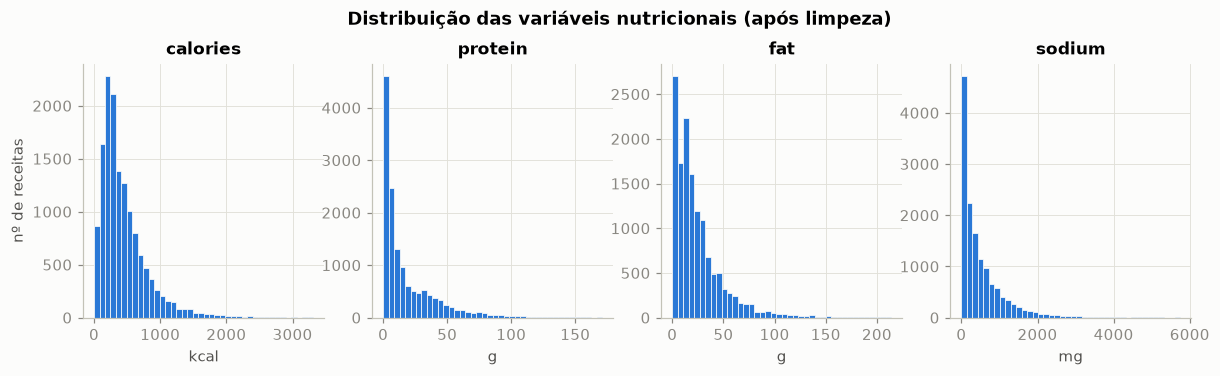

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, col in zip(axes, NUTRI):
    ax.hist(dados[col], bins=40, color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_title(col)
    ax.set_xlabel("kcal" if col == "calories" else ("mg" if col == "sodium" else "g"))
axes[0].set_ylabel("nº de receitas")
fig.suptitle("Distribuição das variáveis nutricionais (após limpeza)", fontweight="bold", y=1.04)
plt.show()

Todas as distribuições são **assimétricas à direita**: a maioria das receitas tem valores baixos/moderados e
poucas têm valores altos. Isso é esperado para variáveis que não podem ser negativas.

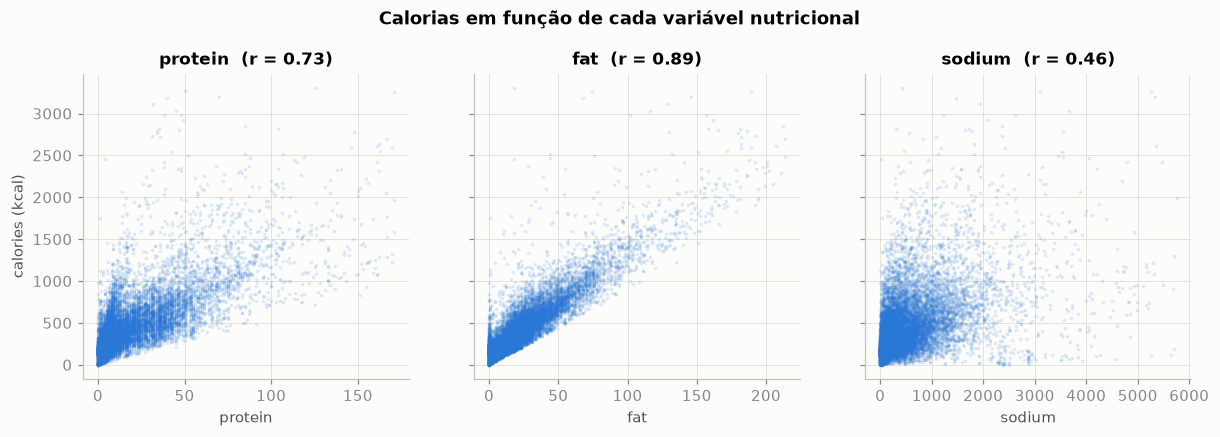

,calories,protein,fat,sodium
calories,1.00,0.73,0.89,0.46
protein,0.73,1.00,0.65,0.53
fat,0.89,0.65,1.00,0.38
sodium,0.46,0.53,0.38,1.00


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, col in zip(axes, MACROS):
    ax.scatter(dados[col], dados[ALVO], s=5, alpha=0.15, color=AZUL, linewidths=0)
    r = dados[col].corr(dados[ALVO])
    ax.set_title(f"{col}  (r = {r:.2f})")
    ax.set_xlabel(col)
axes[0].set_ylabel("calories (kcal)")
fig.suptitle("Calorias em função de cada variável nutricional", fontweight="bold", y=1.04)
plt.show()

dados[NUTRI].corr().round(2)

`fat` tem a relação linear mais forte com `calories`, seguida de `protein`. `sodium` tem relação mais fraca
— o sódio não fornece energia, mas receitas maiores/mais salgadas tendem a ser mais calóricas.

As variáveis preditoras também são correlacionadas entre si, então verificamos a **multicolinearidade** com o
VIF (*Variance Inflation Factor*). Como regra prática, VIF > 5–10 indica problema.

In [11]:
X_vif = sm.add_constant(dados[MACROS])
pd.DataFrame({
    "variável": MACROS,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(MACROS))],
}).round(2)

,variável,VIF
0,protein,2.06
1,fat,1.73
2,sodium,1.39


## 6. Modelagem

Testamos **quatro modelos, um de cada vez**, do mais simples ao mais complexo. Cada um responde a uma pergunta:

| Modelo | Variáveis | Pergunta |
|---|---|---|
| 1. Regressão linear | 3 macronutrientes | Quanto dá para explicar só com proteína, gordura e sódio? |
| 2. Regressão linear | macronutrientes + 332 tags (335) | As tags melhoram o modelo? |
| 3. Regressão linear reduzida | 10 variáveis selecionadas | Dá para manter o resultado com poucas variáveis? |
| 4. Gradient Boosting reduzido | as mesmas 10 variáveis | Um modelo não linear faz melhor? |

Entre os modelos 2 e 3 há uma etapa de **seleção de variáveis** (seção 6.4), que reduz as 335 variáveis para 10.

Depois dos quatro modelos principais há uma **parte extra** (seção 6.7) com três modelos maiores, para mostrar
quanto se ganha ao usar mais variáveis: Lasso, Gradient Boosting com 30 variáveis e Gradient Boosting com todas as 335.

Todos usam **os mesmos dados de treino e de teste**. Cada modelo é apresentado sempre na mesma ordem,
para que possa ser lido e explicado separadamente:

1. **O que é** o modelo;
2. **Ficha do modelo**: métricas e gráfico de calorias reais × previstas;
3. **Variáveis utilizadas e motivo**: quais variáveis entram e por que foram escolhidas;
4. **Interpretação** dos resultados;
5. **Próximo passo**: o que o resultado sugere testar em seguida.

### 6.1 Divisão treino/teste

80% para treino e 20% para teste. O conjunto de teste **não é usado** em nenhuma decisão de modelagem — ele
serve só para a avaliação final.

In [12]:
X = dados[MACROS + tags]
y = dados[ALVO]

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Treino: {X_treino.shape} | Teste: {X_teste.shape}")


def r2_ajustado(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


resultados = []
previsoes = {}
modelos = {}
variaveis_usadas = {}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)


def avaliar(nome, modelo, colunas, p=None, usadas=None):
    # Ajusta no treino, valida com 5-fold CV no treino e avalia no teste
    cv_r2 = cross_val_score(modelo, X_treino[colunas], y_treino, cv=cv, scoring="r2")
    modelo.fit(X_treino[colunas], y_treino)
    pred = modelo.predict(X_teste[colunas])
    p = p(modelo) if callable(p) else len(colunas)
    r2 = r2_score(y_teste, pred)
    previsoes[nome] = pred
    resultados.append({
        "modelo": nome,
        "nº variáveis": p,
        "R² treino": r2_score(y_treino, modelo.predict(X_treino[colunas])),
        "R² CV (média)": cv_r2.mean(),
        "R² CV (desvio)": cv_r2.std(),
        "R² teste": r2,
        "R² ajustado teste": r2_ajustado(r2, len(y_teste), p),
        "RMSE teste": root_mean_squared_error(y_teste, pred),
        "MAE teste": mean_absolute_error(y_teste, pred),
    })
    modelos[nome] = modelo
    variaveis_usadas[nome] = usadas(modelo) if callable(usadas) else list(colunas)
    mostrar(nome)
    return modelo


def descrever(colunas):
    # Lista as variáveis; quando há tags demais, mostra só a contagem
    numericas = [c for c in colunas if c in MACROS]
    etiquetas = [c for c in colunas if c not in MACROS]
    if len(etiquetas) <= 30:
        return ", ".join(numericas + etiquetas)
    return ", ".join(numericas) + f" + {len(etiquetas)} tags"


def mostrar(nome):
    # Ficha do modelo: métricas + gráfico de real x previsto no teste
    r = resultados[-1]
    print(f"=== {nome} ===")
    print(f"Nº de variáveis:          {r['nº variáveis']}")
    print(textwrap.fill("Variáveis:                " + descrever(variaveis_usadas[nome]), width=100, subsequent_indent=" " * 26))
    print(f"R² treino:                {r['R² treino']:.3f}")
    print(f"R² validação cruzada:     {r['R² CV (média)']:.3f} ± {r['R² CV (desvio)']:.3f}")
    print(f"R² teste:                 {r['R² teste']:.3f}")
    print(f"R² ajustado teste:        {r['R² ajustado teste']:.3f}")
    print(f"RMSE teste:               {r['RMSE teste']:.0f} kcal")
    print(f"MAE teste:                {r['MAE teste']:.0f} kcal")

    pred = previsoes[nome]
    fig, ax = plt.subplots(figsize=(4.6, 4.2))
    ax.scatter(y_teste, pred, s=7, alpha=0.25, color=AZUL, linewidths=0)
    lim = [0, y_teste.max()]
    ax.plot(lim, lim, color=LARANJA, linewidth=1.5, label="previsão perfeita")
    ax.set(title=nome, xlabel="calorias reais (kcal)", ylabel="calorias previstas (kcal)")
    ax.legend(frameon=False)
    plt.show()

Treino: (11276, 335) | Teste: (2820, 335)


### 6.2 Modelo 1 — Regressão linear múltipla (só macronutrientes)

Modelo de referência (*baseline*): $\text{calories} = \beta_0 + \beta_1\,\text{protein} + \beta_2\,\text{fat} + \beta_3\,\text{sodium} + \varepsilon$

Usamos o `statsmodels` para obter a tabela completa da regressão (coeficientes, erros-padrão, p-valores, R² e R² ajustado).

In [13]:
ols_macros = sm.OLS(y_treino, sm.add_constant(X_treino[MACROS])).fit()
print(ols_macros.summary())

                            OLS Regression Results                            
Dep. Variable:               calories   R-squared:                       0.843
Model:                            OLS   Adj. R-squared:                  0.843
Method:                 Least Squares   F-statistic:                 2.011e+04
Date:                Mon, 05 Oct 2026   Prob (F-statistic):               0.00
Time:                        08:39:32   Log-Likelihood:                -72120.
No. Observations:               11276   AIC:                         1.442e+05
Df Residuals:                   11272   BIC:                         1.443e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        109.0814      1.993     54.738      0.0

=== 1. Linear (macros) ===
Nº de variáveis:          3
Variáveis:                protein, fat, sodium
R² treino:                0.843
R² validação cruzada:     0.843 ± 0.013
R² teste:                 0.845
R² ajustado teste:        0.845
RMSE teste:               144 kcal
MAE teste:                95 kcal


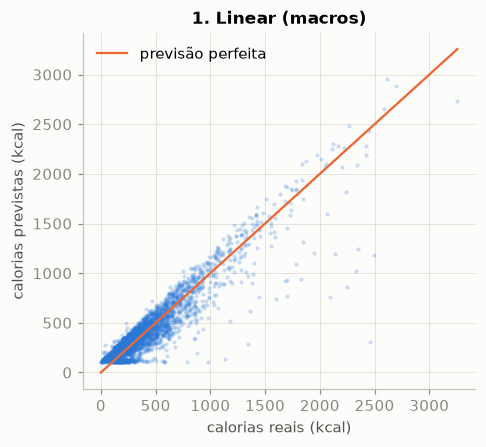

In [14]:
m1 = avaliar("1. Linear (macros)", LinearRegression(), MACROS)

**Variáveis utilizadas e motivo.**

| Variável | Unidade | Por que entra no modelo |
|---|---|---|
| `protein` | g | Proteína fornece cerca de 4 kcal por grama |
| `fat` | g | Gordura fornece cerca de 9 kcal por grama; é a variável mais correlacionada com `calories` (r = 0,89) |
| `sodium` | mg | Não fornece energia, mas é a única outra variável numérica do dataset e indica o tamanho e o tipo da receita |

**Motivo da escolha.** São as únicas variáveis numéricas disponíveis e têm relação física direta com as calorias.
É o ponto de partida natural: o modelo mais simples possível, que serve de referência para todos os outros.

**Interpretação.** Com apenas 3 variáveis o modelo já explica cerca de **84%** da variância das calorias
(R² = 0,843; R² ajustado igual, pois $p$ é muito pequeno em relação a $n$).

- Todos os coeficientes são significativos (p < 0,001).
- `fat` ≈ **10,0 kcal/g** e `protein` ≈ **3,6 kcal/g**, valores próximos dos fatores de Atwater (9 e 4). O modelo
  "redescobriu" uma relação conhecida da nutrição.
- O intercepto (≈ 109 kcal) não é zero: ele absorve a média das calorias vindas dos **carboidratos**, que o modelo não observa.
- Os testes Omnibus/Jarque-Bera rejeitam a normalidade dos resíduos (assimetria e curtose altas) — voltamos a isso na seção 8.

**Próximo passo.** O Modelo 1 não enxerga os carboidratos, que também fornecem calorias. O dataset não tem essa
coluna, mas tem as tags, que dizem se a receita é uma massa, uma sobremesa etc. O próximo modelo testa se elas ajudam.

### 6.3 Modelo 2 — Regressão linear com macronutrientes + tags

Agora incluímos as tags. A hipótese é que elas carregam a informação que falta sobre **carboidratos**.
Como $p$ passa de 3 para centenas, aqui o **R² ajustado** é a métrica relevante.

In [15]:
ols_completo = sm.OLS(y_treino, sm.add_constant(X_treino)).fit()

pd.DataFrame({
    "modelo": ["Linear (macros)", "Linear (macros + tags)"],
    "nº variáveis": [len(MACROS), X_treino.shape[1]],
    "R² treino": [ols_macros.rsquared, ols_completo.rsquared],
    "R² ajustado treino": [ols_macros.rsquared_adj, ols_completo.rsquared_adj],
    "AIC": [ols_macros.aic, ols_completo.aic],
}).round(4)

,modelo,nº variáveis,R² treino,R² ajustado treino,AIC
0,Linear (macros),3,0.8425,0.8425,144247.7368
1,Linear (macros + tags),335,0.8995,0.8965,139845.1224


Teste F parcial: F = 18.7 | gl = 332 | p-valor = 0
Tags com p-valor < 0,05: 107 de 332
=== 2. Linear (macros + tags) ===
Nº de variáveis:          335
Variáveis:                protein, fat, sodium + 332 tags
R² treino:                0.900
R² validação cruzada:     0.892 ± 0.009
R² teste:                 0.894
R² ajustado teste:        0.880
RMSE teste:               120 kcal
MAE teste:                68 kcal


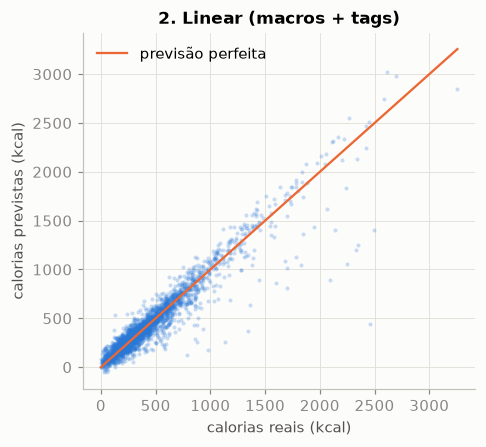

In [16]:
# Teste F parcial: as tags, em conjunto, melhoram o modelo?
f, p_valor, gl = ols_completo.compare_f_test(ols_macros)
print(f"Teste F parcial: F = {f:.1f} | gl = {int(gl)} | p-valor = {p_valor:.3g}")
print(f"Tags com p-valor < 0,05: {(ols_completo.pvalues[tags] < 0.05).sum()} de {len(tags)}")

m2 = avaliar("2. Linear (macros + tags)", LinearRegression(), MACROS + tags)

**Variáveis utilizadas e motivo.**

| Grupo | Quantidade | Variáveis |
|---|---|---|
| Macronutrientes | 3 | `protein`, `fat`, `sodium` |
| Tags | 332 | Todas as tags com pelo menos 50 receitas, exceto `low cal` (lista na variável `tags`) |

**Motivo da escolha.** A ideia é testar a hipótese de que as tags carregam a informação de carboidratos que falta.
Usamos **todas** as tags, sem escolher nenhuma à mão, por dois motivos: evita que a escolha do analista influencie
o resultado, e mostra o máximo que uma regressão linear consegue extrair delas.

**Interpretação.** O R² ajustado no treino sobe de 0,843 para **0,897**, mesmo com a penalização por 332 variáveis
a mais; o AIC também cai. O teste F parcial rejeita a hipótese de que todos os coeficientes das tags são zero
(p ≈ 0), ou seja, as tags **em conjunto** agregam informação.

Por outro lado, só 107 das 332 tags são individualmente significativas a 5%. Há muitas variáveis irrelevantes
no modelo, o que motiva o uso de um método de seleção de variáveis.

**Próximo passo.** As tags ajudam, mas 335 variáveis é demais: a maioria não é significativa e o modelo fica
difícil de explicar. O próximo passo é descobrir **quais** variáveis realmente importam.

### 6.4 Seleção de variáveis com Lasso

O Modelo 2 tem 335 variáveis, e a maioria contribui pouco. Para simplificar, usamos o **Lasso**, uma regressão
linear com penalidade L1:

$$\min_\beta \; \sum (y_i - \hat y_i)^2 + \alpha \sum |\beta_j|$$

Quanto maior o $\alpha$, mais coeficientes são zerados. Com $\alpha$ muito alto nenhuma variável entra no modelo;
ao diminuí-lo aos poucos, as variáveis vão entrando **da mais importante para a menos importante**
(*caminho de regularização*). Essa ordem de entrada serve como ranking das variáveis.

A seleção usa **somente os dados de treino**.

In [17]:
from sklearn.linear_model import lasso_path

Z_treino = StandardScaler().fit_transform(X_treino)
alphas, coefs, _ = lasso_path(Z_treino, y_treino - y_treino.mean(), n_alphas=200)

# Ordem em que cada variável entra no modelo conforme alpha diminui
ordem = []
for j in range(coefs.shape[1]):
    for i in np.flatnonzero(coefs[:, j]):
        if X.columns[i] not in ordem:
            ordem.append(X.columns[i])

print("Primeiras 20 variáveis, em ordem de entrada:")
for pos, var in enumerate(ordem[:20], start=1):
    print(f"{pos:>2}. {var}")

Primeiras 20 variáveis, em ordem de entrada:
 1. fat
 2. protein
 3. sodium
 4. pasta
 5. dessert
 6. fruit
 7. sugar conscious
 8. alcoholic
 9. drink
10. no-cook
11. pear
12. rice
13. bake
14. cake
15. prune
16. quick & easy
17. sweet potato/yam
18. cranberry
19. fall
20. low carb


**Quantas variáveis usar?** Ajustamos os dois tipos de modelo com as $k$ primeiras variáveis do ranking e
medimos o R² por validação cruzada (no treino) para vários valores de $k$.

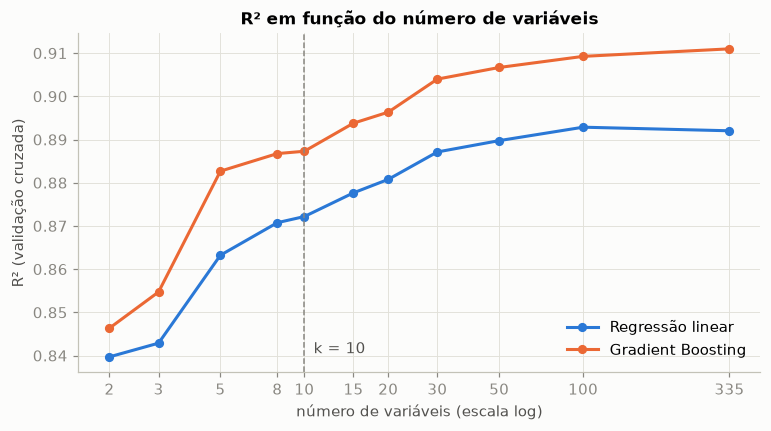

,Regressão linear,Gradient Boosting
k,,
2,0.8397,0.8463
3,0.8429,0.8547
5,0.8632,0.8827
8,0.8708,0.8867
10,0.8722,0.8873
15,0.8777,0.8938
20,0.8808,0.8963
30,0.8871,0.9040
50,0.8897,0.9067


In [18]:
ks = [2, 3, 5, 8, 10, 15, 20, 30, 50, 100, X.shape[1]]
curva = []
for k in ks:
    cols = ordem[:k] if k < X.shape[1] else list(X.columns)
    curva.append({
        "k": k,
        "Regressão linear": cross_val_score(LinearRegression(), X_treino[cols], y_treino, cv=cv, scoring="r2").mean(),
        "Gradient Boosting": cross_val_score(HistGradientBoostingRegressor(random_state=SEED), X_treino[cols], y_treino, cv=cv, scoring="r2").mean(),
    })
curva = pd.DataFrame(curva).set_index("k")

K = 10
fig, ax = plt.subplots(figsize=(8, 4))
for nome, cor in [("Regressão linear", AZUL), ("Gradient Boosting", LARANJA)]:
    ax.plot(curva.index, curva[nome], color=cor, linewidth=2, marker="o", markersize=5, label=nome)
ax.axvline(K, color=CINZA, linewidth=1, linestyle="--")
ax.text(K * 1.08, curva.min().min(), f"k = {K}", color="#52514e", va="bottom")
ax.set_xscale("log")
ax.set_xticks(ks)
ax.set_xticklabels(ks)
ax.minorticks_off()
ax.set(xlabel="número de variáveis (escala log)", ylabel="R² (validação cruzada)",
       title="R² em função do número de variáveis")
ax.legend(frameon=False, loc="lower right")
plt.show()

curva.round(4)

**Interpretação.** O ganho se concentra nas primeiras variáveis: de 3 para 5 variáveis o R² do Gradient Boosting
sobe de 0,855 para 0,883. Depois a curva achata — ir de 10 para 335 variáveis acrescenta só cerca de 0,02 de R².

Escolhemos **k = 10**: os 3 macronutrientes e 7 tags. É uma redução de 97% no número de variáveis
(de 335 para 10) em troca de cerca de 2 pontos percentuais de R².

In [19]:
SELECIONADAS = ordem[:K]
print(f"{K} variáveis selecionadas:")
print(SELECIONADAS)

10 variáveis selecionadas:
['fat', 'protein', 'sodium', 'pasta', 'dessert', 'fruit', 'sugar conscious', 'alcoholic', 'drink', 'no-cook']


### 6.5 Modelo 3 — Regressão linear reduzida (10 variáveis)

A mesma regressão linear dos modelos 1 e 2, agora só com as 10 variáveis selecionadas. Com poucas variáveis,
a tabela da regressão volta a ser legível e o modelo pode ser escrito como uma equação.

In [20]:
ols_reduzido = sm.OLS(y_treino, sm.add_constant(X_treino[SELECIONADAS])).fit()
print(ols_reduzido.summary())

                            OLS Regression Results                            
Dep. Variable:               calories   R-squared:                       0.872
Model:                            OLS   Adj. R-squared:                  0.872
Method:                 Least Squares   F-statistic:                     7674.
Date:                Mon, 05 Oct 2026   Prob (F-statistic):               0.00
Time:                        08:39:53   Log-Likelihood:                -70952.
No. Observations:               11276   AIC:                         1.419e+05
Df Residuals:                   11265   BIC:                         1.420e+05
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              63.5422      2.372     

=== 3. Linear (10 variáveis) ===
Nº de variáveis:          10
Variáveis:                fat, protein, sodium, pasta, dessert, fruit, sugar conscious, alcoholic,
                          drink, no-cook
R² treino:                0.872
R² validação cruzada:     0.872 ± 0.012
R² teste:                 0.877
R² ajustado teste:        0.877
RMSE teste:               129 kcal
MAE teste:                79 kcal


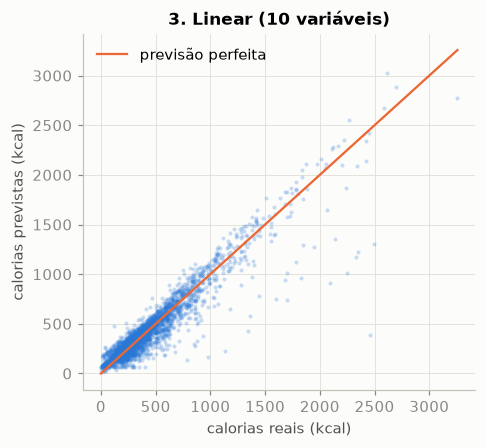

In [21]:
m3 = avaliar("3. Linear (10 variáveis)", LinearRegression(), SELECIONADAS)

**Variáveis utilizadas e motivo.**

| # | Variável | Tipo | Por que entra no modelo |
|---|---|---|---|
| 1 | `fat` | numérica | Gordura: 9 kcal por grama |
| 2 | `protein` | numérica | Proteína: 4 kcal por grama |
| 3 | `sodium` | numérica | Indica o tamanho e o tipo da receita |
| 4 | `pasta` | tag | Massa: muito carboidrato |
| 5 | `dessert` | tag | Sobremesa: muito açúcar |
| 6 | `fruit` | tag | Fruta: açúcar natural |
| 7 | `sugar conscious` | tag | Receita com pouco açúcar: menos carboidrato |
| 8 | `alcoholic` | tag | Álcool fornece cerca de 7 kcal por grama e não aparece em nenhuma outra coluna |
| 9 | `drink` | tag | Bebida: calorias vêm de açúcar ou álcool, não de gordura ou proteína |
| 10 | `no-cook` | tag | Receitas sem cozimento (saladas, molhos): pouco carboidrato |

**Motivo da escolha.** São as 10 primeiras variáveis do ranking do Lasso (seção 6.4), ou seja, foram escolhidas
pelos dados, e não à mão. A curva de validação cruzada mostrou que o ganho se concentra nelas. Além dos três
macronutrientes, todas as tags selecionadas indicam **carboidrato ou álcool** — exatamente a informação que falta no dataset.

**Interpretação.** Com 10 variáveis o modelo atinge R² de teste de **0,877** (R² ajustado igual, pois $p$ é pequeno),
contra 0,845 do Modelo 1 e 0,894 do Modelo 2 com 335 variáveis. O erro absoluto médio é de 79 kcal.

Todas as 10 variáveis são significativas (p < 0,001) e o modelo cabe em uma equação:

$$\begin{aligned}\text{calories} = {} & 63{,}5 + 9{,}87\,\text{fat} + 3{,}99\,\text{protein} + 0{,}051\,\text{sodium} \\ & + 148{,}7\,\text{pasta} + 105{,}8\,\text{dessert} + 71{,}3\,\text{drink} + 64{,}7\,\text{fruit} + 54{,}0\,\text{alcoholic} \\ & - 27{,}4\,\text{sugar conscious} - 46{,}0\,\text{no-cook}\end{aligned}$$

Os coeficientes de gordura (9,87) e proteína (3,99) ficam praticamente iguais aos fatores de Atwater (9 e 4).
R² de treino, validação cruzada e teste são quase idênticos: não há overfitting.

**Próximo passo.** A regressão linear supõe que cada variável soma um valor fixo de calorias. Isso pode não ser
verdade: uma sobremesa com muita gordura pode se comportar de modo diferente de uma com pouca. O próximo modelo
usa as mesmas variáveis com um algoritmo não linear.

### 6.6 Modelo 4 — Gradient Boosting reduzido (10 variáveis)

Modelo não linear baseado em árvores de decisão construídas em sequência, cada uma corrigindo os erros das
anteriores. Ele captura **não linearidades e interações** (por exemplo, o efeito de `dessert` depender da
quantidade de gordura) que a regressão linear não captura. Usa as mesmas 10 variáveis do Modelo 3 e os
hiperparâmetros padrão do scikit-learn.

=== 4. Gradient Boosting (10 variáveis) ===
Nº de variáveis:          10
Variáveis:                fat, protein, sodium, pasta, dessert, fruit, sugar conscious, alcoholic,
                          drink, no-cook
R² treino:                0.914
R² validação cruzada:     0.887 ± 0.010
R² teste:                 0.887
R² ajustado teste:        0.887
RMSE teste:               123 kcal
MAE teste:                73 kcal


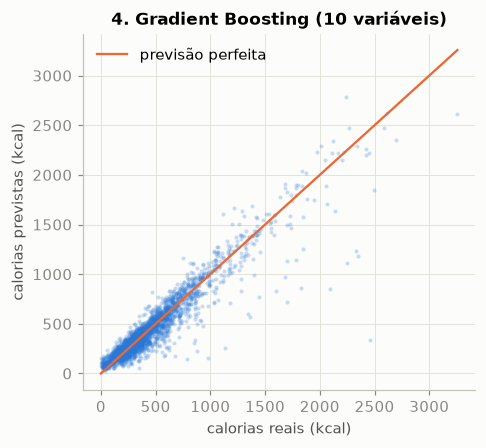


Hiperparâmetros: {'loss': 'squared_error', 'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}


In [22]:
m4 = avaliar("4. Gradient Boosting (10 variáveis)", HistGradientBoostingRegressor(random_state=SEED), SELECIONADAS)

print("\nHiperparâmetros:", {k: m4.get_params()[k] for k in ["loss", "learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf"]})

**Variáveis utilizadas e motivo.** As **mesmas 10 variáveis do Modelo 3**: `fat`, `protein`, `sodium`, `pasta`,
`dessert`, `fruit`, `sugar conscious`, `alcoholic`, `drink` e `no-cook`.

**Motivo da escolha.** Manter as variáveis fixas e trocar só o algoritmo torna a comparação justa: qualquer
diferença de desempenho entre os modelos 3 e 4 vem do tipo de modelo (linear × não linear), e não das variáveis.

**Interpretação.** Com as mesmas 10 variáveis, o Gradient Boosting atinge R² de teste de **0,887** e R² ajustado
de **0,887**, com erro absoluto médio de 73 kcal. É o melhor dos modelos reduzidos, cerca de 1 ponto percentual acima
da regressão linear com as mesmas variáveis.

O R² de treino (0,914) é maior que o de teste, o que mostra um pouco de sobreajuste, normal em modelos de
árvores; a validação cruzada (0,887) coincide com o teste e confirma o desempenho real.

**Próximo passo.** Com 10 variáveis os modelos são simples e já explicam 88% a 89% da variância. Resta saber
quanto se ganharia abrindo mão da simplicidade — é o que a parte extra responde.

### 6.7 Parte extra — modelos com mais variáveis

Os modelos 3 e 4 priorizam a simplicidade (10 variáveis). Esta parte mostra o outro lado da troca: o que
acontece quando se usam mais variáveis. São três modelos, cada um com a sua ficha.

| Modelo extra | Variáveis | Pergunta |
|---|---|---|
| 5. Lasso | 335, com seleção automática | Qual o melhor modelo **linear** possível com as tags? |
| 6. Gradient Boosting | 30 selecionadas | Um meio-termo entre 10 e 335 compensa? |
| 7. Gradient Boosting | todas as 335 | Qual o teto de desempenho com estes dados? |

#### Modelo 5 — Lasso

Regressão linear com penalidade L1 (a mesma técnica usada na seção 6.4 para ordenar as variáveis). Aqui o Lasso
é usado como **modelo de previsão**: recebe as 335 variáveis e a força da penalidade ($\alpha$) é escolhida por
validação cruzada (`LassoCV`), de modo a maximizar o desempenho, e não a simplicidade. As variáveis são
padronizadas antes, pois a penalidade depende da escala.

=== 5. Lasso ===
Nº de variáveis:          245
Variáveis:                protein, fat, sodium + 242 tags
R² treino:                0.898
R² validação cruzada:     0.893 ± 0.010
R² teste:                 0.894
R² ajustado teste:        0.884
RMSE teste:               119 kcal
MAE teste:                67 kcal


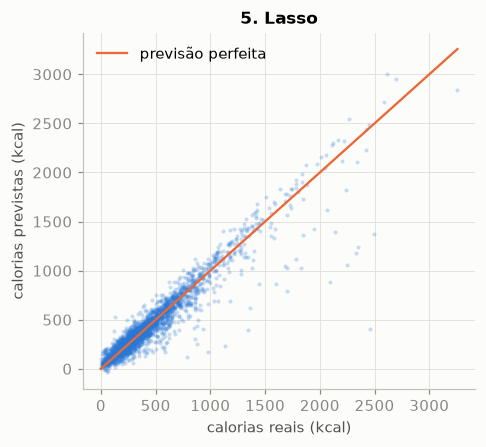

alpha escolhido: 0.754
Variáveis mantidas: 245 de 335


In [23]:
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED))
n_selecionadas = lambda m: int((m[-1].coef_ != 0).sum())
mantidas = lambda m: [c for c, b in zip(MACROS + tags, m[-1].coef_) if b != 0]
m5 = avaliar("5. Lasso", lasso, MACROS + tags, p=n_selecionadas, usadas=mantidas)

print(f"alpha escolhido: {m5[-1].alpha_:.3f}")
print(f"Variáveis mantidas: {n_selecionadas(m5)} de {X.shape[1]}")

**Variáveis utilizadas e motivo.** O modelo recebe as 335 variáveis e mantém **245**: os 3 macronutrientes e
242 tags. As outras 90 tags têm o coeficiente zerado e saem do modelo.

**Motivo da escolha.** Aqui a escolha é feita **pelo próprio modelo**. Em vez de fixarmos um número de variáveis,
deixamos a validação cruzada decidir a força da penalidade que dá o melhor desempenho. O resultado mostra quantas
variáveis um modelo linear "quer" usar quando o único critério é prever bem.

Coeficientes dos macronutrientes:
protein    4.659
fat        9.894
sodium     0.045


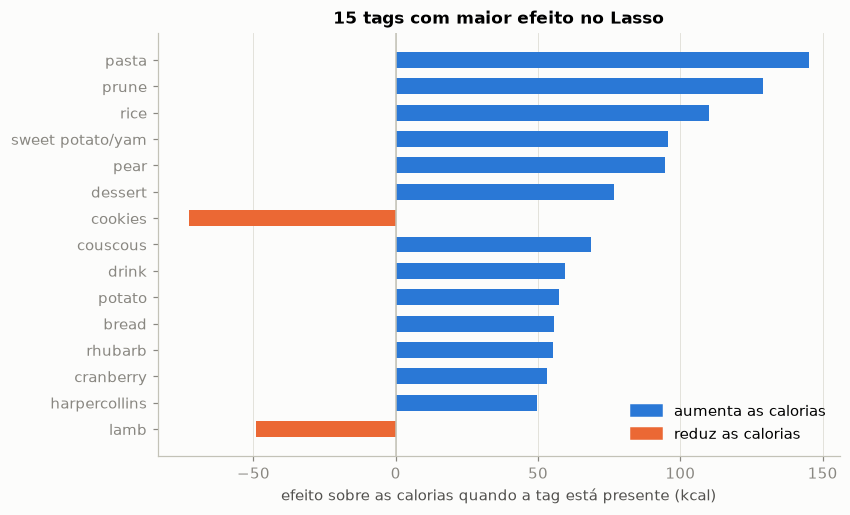

In [24]:
# Coeficientes do Lasso convertidos de volta para a escala original
coef_lasso = pd.Series(m5[-1].coef_ / m5[0].scale_, index=MACROS + tags)
print("Coeficientes dos macronutrientes:")
print(coef_lasso[MACROS].round(3).to_string())

top = coef_lasso[tags].reindex(coef_lasso[tags].abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[AZUL if v > 0 else LARANJA for v in top.values], height=0.6)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("efeito sobre as calorias quando a tag está presente (kcal)")
ax.set_title("15 tags com maior efeito no Lasso")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=LARANJA)],
          labels=["aumenta as calorias", "reduz as calorias"], frameon=False, loc="lower right")
plt.show()

**Interpretação.** O Lasso manteve 245 das 335 variáveis e atinge R² de teste de **0,894** e R² ajustado de **0,884**.
É o melhor dos modelos lineares: tem o mesmo R² do Modelo 2 com 90 variáveis a menos, e supera o Modelo 3
(R² ajustado de 0,877) em 0,007 — mas precisa de 245 variáveis em vez de 10.

Os coeficientes de proteína (≈ 4,7 kcal/g) e gordura (≈ 9,9 kcal/g) continuam próximos dos valores teóricos, e
as tags com maior efeito são novamente fontes de carboidrato (`pasta`, `rice`, `sweet potato/yam`, `couscous`,
`potato`, `bread`, frutas e `dessert`). Tags como `harpercollins` (uma editora) não têm significado causal;
são correlações com o tipo de receita publicado por aquela fonte.

#### Modelo 6 — Gradient Boosting com 30 variáveis

O mesmo Gradient Boosting do Modelo 4, agora com as **30 primeiras variáveis** do ranking da seção 6.4.

30 variáveis selecionadas:
['fat', 'protein', 'sodium', 'pasta', 'dessert', 'fruit', 'sugar conscious', 'alcoholic', 'drink', 'no-cook', 'pear', 'rice', 'bake', 'cake', 'prune', 'quick & easy', 'sweet potato/yam', 'cranberry', 'fall', 'low carb', 'cookies', 'potato', 'salad', 'bread', 'kidney friendly', 'marinate', 'garlic', 'bean', 'dried fruit', 'kosher'] 



=== 6. Gradient Boosting (30 variáveis) ===
Nº de variáveis:          30
Variáveis:                fat, protein, sodium, pasta, dessert, fruit, sugar conscious, alcoholic,
                          drink, no-cook, pear, rice, bake, cake, prune, quick & easy, sweet
                          potato/yam, cranberry, fall, low carb, cookies, potato, salad, bread,
                          kidney friendly, marinate, garlic, bean, dried fruit, kosher
R² treino:                0.932
R² validação cruzada:     0.904 ± 0.010
R² teste:                 0.898
R² ajustado teste:        0.897
RMSE teste:               117 kcal
MAE teste:                66 kcal


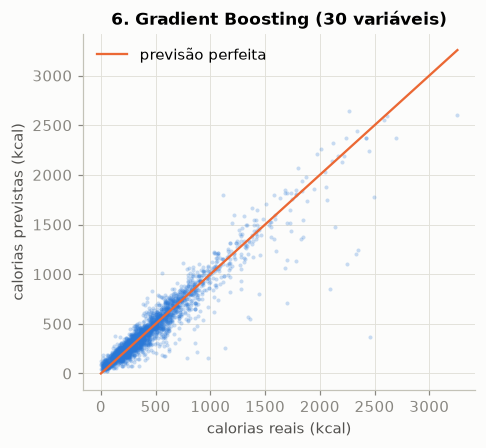

In [25]:
SELECIONADAS_30 = ordem[:30]
print("30 variáveis selecionadas:")
print(SELECIONADAS_30, "\n")

m6 = avaliar("6. Gradient Boosting (30 variáveis)", HistGradientBoostingRegressor(random_state=SEED), SELECIONADAS_30)

**Variáveis utilizadas e motivo.** As 30 primeiras do ranking do Lasso: as 10 dos modelos 3 e 4 e mais 20 tags.

| Grupo | Variáveis | O que indicam |
|---|---|---|
| Macronutrientes (3) | `fat`, `protein`, `sodium` | Gordura, proteína e tamanho da receita |
| Fontes de carboidrato (6) | `pasta`, `rice`, `potato`, `sweet potato/yam`, `bread`, `bean` | Amido |
| Sobremesas e doces (3) | `dessert`, `cake`, `cookies` | Açúcar |
| Frutas (5) | `fruit`, `pear`, `prune`, `cranberry`, `dried fruit` | Açúcar natural |
| Bebidas e álcool (2) | `drink`, `alcoholic` | Calorias de açúcar ou álcool |
| Dieta (4) | `sugar conscious`, `low carb`, `kidney friendly`, `kosher` | Restrições que mudam a composição da receita |
| Preparo (4) | `no-cook`, `bake`, `marinate`, `quick & easy` | Tipo de receita (assados costumam levar farinha; receitas sem cozimento, não) |
| Outras (3) | `salad`, `garlic`, `fall` | Pratos leves, pratos salgados e receitas de outono |

**Motivo da escolha.** Na curva de validação cruzada da seção 6.4, o R² do Gradient Boosting ainda sobe de
0,887 para 0,904 entre 10 e 30 variáveis, mas depois quase não muda: as 305 variáveis seguintes acrescentam só 0,007.
O valor 30 é o ponto em que a curva começa a achatar. A maior parte das variáveis novas reforça o mesmo sinal das
anteriores: **mais indicadores de carboidrato**.

**Interpretação.** Com 30 variáveis o R² de teste sobe para **0,898** e o R² ajustado para **0,897**, com erro
absoluto médio de 66 kcal. São 20 variáveis a mais que o Modelo 4 em troca de 1 ponto percentual de R² ajustado.

As 20 variáveis novas são, na maioria, mais indicadores de carboidrato (`rice`, `cake`, `potato`, `bread`,
`sweet potato/yam`, `cookies`, frutas) e de receitas com pouco carboidrato (`low carb`, `salad`).

#### Modelo 7 — Gradient Boosting com todas as variáveis

O mesmo Gradient Boosting, com as **335 variáveis**, sem nenhuma seleção.

=== 7. Gradient Boosting (335 variáveis) ===
Nº de variáveis:          335
Variáveis:                protein, fat, sodium + 332 tags
R² treino:                0.943
R² validação cruzada:     0.911 ± 0.009
R² teste:                 0.905
R² ajustado teste:        0.892
RMSE teste:               113 kcal
MAE teste:                62 kcal


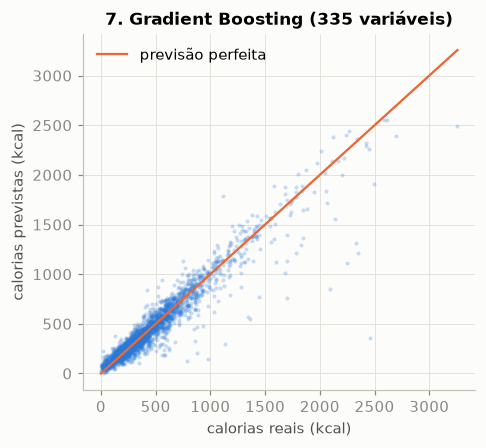

In [26]:
m7 = avaliar("7. Gradient Boosting (335 variáveis)", HistGradientBoostingRegressor(random_state=SEED), MACROS + tags)

**Variáveis utilizadas e motivo.** Todas as **335**: os 3 macronutrientes e as 332 tags (as mesmas do Modelo 2).

**Motivo da escolha.** Serve de **teto de referência**: é o máximo que conseguimos extrair destes dados sem
nenhuma seleção. Comparar os modelos 4 e 6 com ele mostra quanto desempenho se perde ao simplificar.

**Interpretação.** É o modelo com o maior R² de teste de todo o trabalho: **0,905**, com erro absoluto médio de 62 kcal.
Porém, com 335 variáveis, o R² ajustado cai para **0,892** — abaixo do Modelo 6 (0,897), que usa só 30.

Ou seja: as 305 variáveis adicionais melhoram o R² em 0,007, mas não o suficiente para compensar a penalização.
O R² de treino (0,943) também se afasta mais do de teste, sinal de um pouco mais de sobreajuste.

## 7. Comparação dos modelos

Agora que cada modelo foi visto separadamente, a tabela abaixo coloca os sete lado a lado:
os quatro principais (1 a 4) e os três da parte extra (5 a 7).

In [27]:
tabela = pd.DataFrame(resultados).set_index("modelo")
tabela.round(4)

,nº variáveis,R² treino,R² CV (média),R² CV (desvio),R² teste,R² ajustado teste,RMSE teste,MAE teste
modelo,,,,,,,,
1. Linear (macros),3,0.8425,0.8429,0.0129,0.8452,0.8450,144.3676,95.1725
2. Linear (macros + tags),335,0.8995,0.8920,0.0092,0.8938,0.8795,119.5546,68.3377
3. Linear (10 variáveis),10,0.8720,0.8722,0.0119,0.8770,0.8765,128.7000,78.5724
4. Gradient Boosting (10 variáveis),10,0.9138,0.8873,0.0096,0.8873,0.8869,123.1488,72.5291
5. Lasso,245,0.8984,0.8929,0.0100,0.8943,0.8843,119.2601,67.3546
6. Gradient Boosting (30 variáveis),30,0.9317,0.9040,0.0101,0.8983,0.8972,116.9906,66.2007
7. Gradient Boosting (335 variáveis),335,0.9429,0.9110,0.0093,0.9049,0.8920,113.1720,62.1245


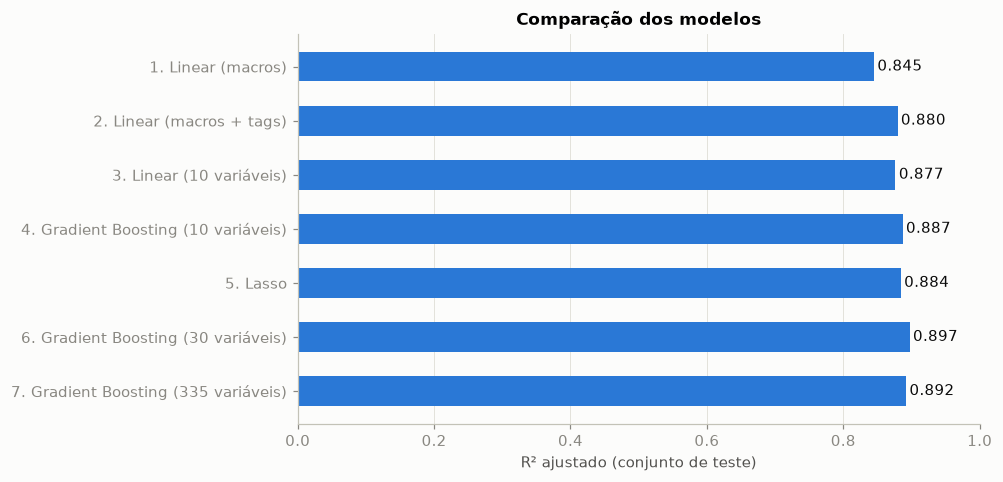

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.6))
nomes = tabela.index[::-1]
valores = tabela.loc[nomes, "R² ajustado teste"]
ax.barh(nomes, valores, color=AZUL, height=0.55)
for i, v in enumerate(valores):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", color="#0b0b0b")
ax.set_xlim(0, 1)
ax.set_xlabel("R² ajustado (conjunto de teste)")
ax.set_title("Comparação dos modelos")
ax.grid(axis="y", visible=False)
plt.show()

**Interpretação.**

| Critério | Modelo | Variáveis | R² teste | R² ajustado teste |
|---|---|---|---|---|
| Maior R² ajustado | 6. Gradient Boosting | 30 | 0,898 | **0,897** |
| Maior R² | 7. Gradient Boosting | 335 | **0,905** | 0,892 |
| Mais simples com bom desempenho | 4. Gradient Boosting | 10 | 0,887 | 0,887 |
| Melhor modelo com equação | 3. Regressão linear | 10 | 0,877 | 0,877 |

- Pelo **R² ajustado**, que é a métrica adequada para comparar modelos com números de variáveis diferentes, o melhor
  é o **Modelo 6** (Gradient Boosting com 30 variáveis): 0,897.
- O **Modelo 7** tem o maior R² bruto (0,905), mas é penalizado pelas 335 variáveis e fica com R² ajustado de 0,892.
- O **Modelo 4** fica a 1 ponto percentual do melhor usando um terço das variáveis do Modelo 6.
- Entre os lineares, o **Lasso** (0,884) supera a regressão com 10 variáveis (0,877), mas precisa de 245 variáveis.
- Todos os modelos com tags ficam entre 0,877 e 0,897 de R² ajustado: a diferença entre eles é pequena perto do
  salto dado pelas primeiras tags sobre o Modelo 1 (0,845).
- Em todos os modelos o R² da validação cruzada é próximo do R² de teste, com desvio de cerca de 0,01: os resultados são estáveis.

## 8. Diagnóstico dos resíduos

Analisamos os resíduos ($e_i = y_i - \hat y_i$) no conjunto de teste para o modelo linear reduzido (Modelo 3),
para verificar os pressupostos da regressão linear.

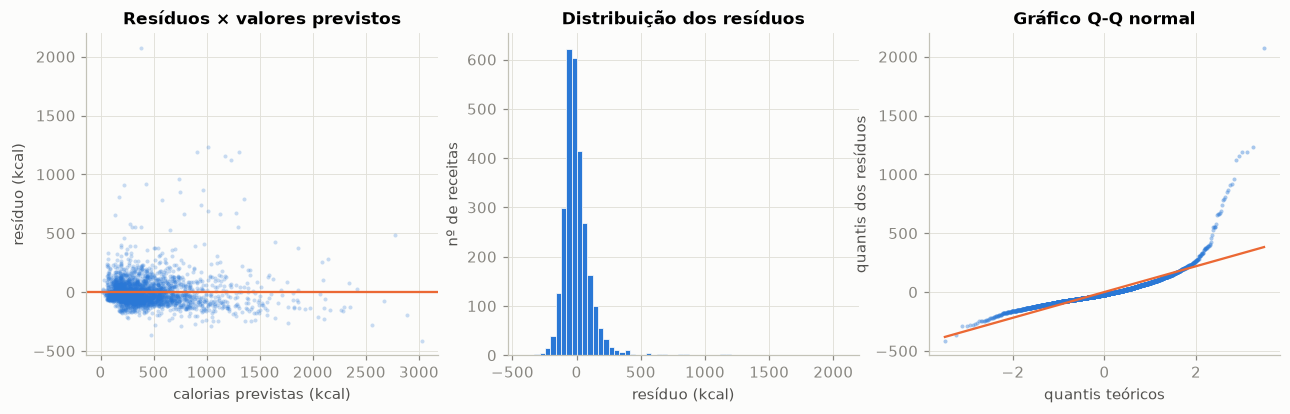

Média dos resíduos: 0.49 kcal | Assimetria: 4.45 | Curtose: 43.06


In [29]:
pred = previsoes["3. Linear (10 variáveis)"]
residuos = y_teste - pred

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

axes[0].scatter(pred, residuos, s=7, alpha=0.25, color=AZUL, linewidths=0)
axes[0].axhline(0, color=LARANJA, linewidth=1.5)
axes[0].set(title="Resíduos × valores previstos", xlabel="calorias previstas (kcal)", ylabel="resíduo (kcal)")

axes[1].hist(residuos, bins=60, color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set(title="Distribuição dos resíduos", xlabel="resíduo (kcal)", ylabel="nº de receitas")

(osm, osr), (incl, inter, _) = stats.probplot(residuos, dist="norm")
axes[2].scatter(osm, osr, s=7, alpha=0.4, color=AZUL, linewidths=0)
axes[2].plot(osm, incl * osm + inter, color=LARANJA, linewidth=1.5)
axes[2].set(title="Gráfico Q-Q normal", xlabel="quantis teóricos", ylabel="quantis dos resíduos")
plt.show()

print(f"Média dos resíduos: {residuos.mean():.2f} kcal | Assimetria: {stats.skew(residuos):.2f} | Curtose: {stats.kurtosis(residuos):.2f}")

**Interpretação.**

- Os resíduos têm média praticamente zero: o modelo não é enviesado.
- O gráfico de resíduos × previstos mostra dispersão crescente com o valor previsto (**heterocedasticidade**):
  receitas mais calóricas têm erros maiores em valor absoluto.
- A distribuição é concentrada em torno de zero, mas com **cauda longa à direita** (assimetria ≈ 4,5), visível
  também no Q-Q. São receitas em que o modelo **subestima** as calorias — tipicamente receitas ricas em
  carboidrato/açúcar que nenhuma das tags selecionadas sinaliza.

Portanto, os pressupostos de homocedasticidade e normalidade dos erros do OLS **não são plenamente atendidos**.
Isso não invalida as previsões nem o R², mas afeta a confiabilidade dos p-valores e intervalos de confiança.

## 9. Interpretação das variáveis

### Modelo 3: coeficientes

Na regressão linear, cada coeficiente é o efeito da variável em kcal, mantendo as demais constantes.

Intercepto: 63.5 kcal

Variáveis numéricas (kcal por unidade):
fat        9.872
protein    3.995
sodium     0.051


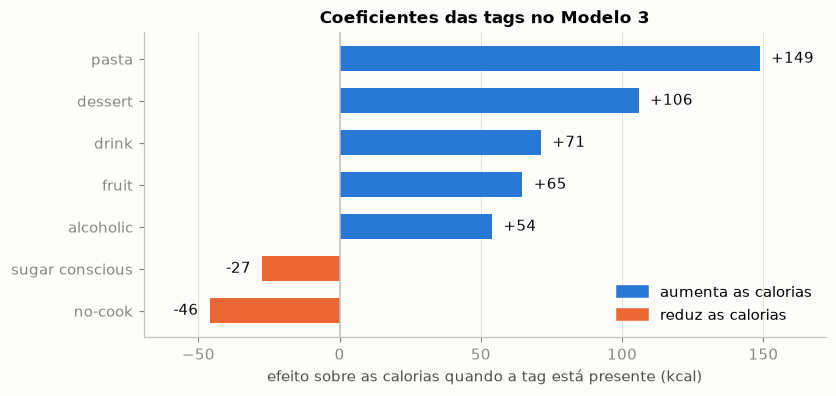

In [30]:
coef = ols_reduzido.params.drop("const")
print(f"Intercepto: {ols_reduzido.params['const']:.1f} kcal\n")
print("Variáveis numéricas (kcal por unidade):")
print(coef[[c for c in SELECIONADAS if c in MACROS]].round(3).to_string())

coef_tags = coef[[c for c in SELECIONADAS if c not in MACROS]].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(coef_tags.index, coef_tags.values, color=[AZUL if v > 0 else LARANJA for v in coef_tags.values], height=0.6)
for i, v in enumerate(coef_tags.values):
    ax.text(v + (4 if v > 0 else -4), i, f"{v:+.0f}", va="center", ha="left" if v > 0 else "right", color="#0b0b0b")
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.margins(x=0.12)
ax.set_xlabel("efeito sobre as calorias quando a tag está presente (kcal)")
ax.set_title("Coeficientes das tags no Modelo 3")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=LARANJA)],
          labels=["aumenta as calorias", "reduz as calorias"], frameon=False, loc="lower right")
plt.show()

**Interpretação.**

- Cada grama de gordura acrescenta cerca de 9,9 kcal e cada grama de proteína cerca de 4,0 kcal.
- As tags com efeito positivo indicam **carboidratos ou álcool**, que o dataset não mede diretamente: uma receita
  com `pasta` tem em média 149 kcal a mais do que outra com a mesma gordura e proteína; `dessert` (açúcar), +106;
  `drink`, +71; `fruit`, +65; `alcoholic`, +54.
- As tags com efeito negativo indicam **menos carboidrato**: `sugar conscious` (receitas com pouco açúcar), −27;
  `no-cook` (receitas sem cozimento, como saladas e molhos), −46.
- O intercepto (63,5 kcal) é a média de calorias não explicadas por nenhuma das variáveis.

As tags funcionam, portanto, como substitutas (*proxy*) da variável de carboidratos que falta.

### Modelo 4: importância das variáveis

O Gradient Boosting não tem coeficientes, então usamos a **importância por permutação**: embaralha-se uma
variável por vez no conjunto de teste e mede-se quanto o R² cai. Quanto maior a queda, mais o modelo depende dela.

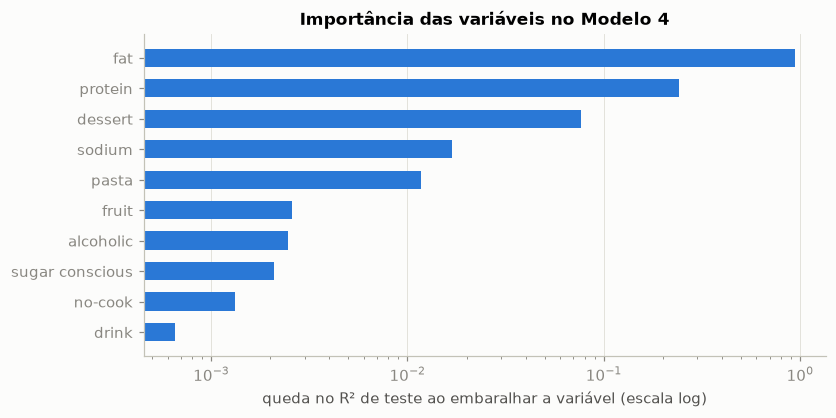

fat                0.9392
protein            0.2415
dessert            0.0770
sodium             0.0169
pasta              0.0117
fruit              0.0026
alcoholic          0.0025
sugar conscious    0.0021
no-cook            0.0013
drink              0.0007
dtype: float64

In [31]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(m4, X_teste[SELECIONADAS], y_teste, n_repeats=10, random_state=SEED, scoring="r2")
importancia = pd.Series(perm.importances_mean, index=SELECIONADAS).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
ax.set_xscale("log")
ax.set_xlabel("queda no R² de teste ao embaralhar a variável (escala log)")
ax.set_title("Importância das variáveis no Modelo 4")
ax.grid(axis="y", visible=False)
plt.show()

importancia[::-1].round(4)

**Interpretação.** O Modelo 4 depende sobretudo de `fat` (embaralhá-la derruba o R² em 0,94) e de `protein` (0,24).
Entre as tags, `dessert` é de longe a mais importante, seguida de `pasta`. A ordem é coerente com os coeficientes do Modelo 3.

## 10. Conclusões

- A variável `calories` pode ser prevista com alta precisão: todos os modelos com tags explicam entre 88% e 90% da variância no teste.
- **Melhor modelo pelo R² ajustado: Gradient Boosting com 30 variáveis** (Modelo 6), com **R² = 0,898** e
  **R² ajustado = 0,897** no conjunto de teste e erro absoluto médio de 66 kcal.
- **Versão mais simples: Gradient Boosting com 10 variáveis** (Modelo 4), com R² e R² ajustado de 0,887.
- **Versão com equação: regressão linear com 10 variáveis** (Modelo 3), com R² ajustado de 0,877. Seus coeficientes
  (≈ 4,0 kcal/g de proteína e ≈ 9,9 kcal/g de gordura) são coerentes com os fatores de Atwater.
- Usar todas as 335 variáveis dá o maior R² bruto (0,905), mas não o maior R² ajustado (0,892): mais variáveis
  nem sempre significam um modelo melhor.
- Só os três macronutrientes já explicam 84% da variância. As tags acrescentam de 3 a 6 pontos percentuais,
  por indicarem a presença de carboidratos e álcool, que não estão no dataset.
- A variável `rating` foi descartada como alvo por não ter relação com as variáveis disponíveis.

### Limitações

- **Carboidratos ausentes.** É a principal fonte de erro: as tags são apenas um indicador indireto da quantidade de carboidrato.
- **Heterocedasticidade e resíduos não normais.** Não afetam as previsões nem o R², mas os erros-padrão e
  p-valores do OLS devem ser lidos com cautela. Uma alternativa seria usar erros-padrão robustos (HC3) ou modelar `log(calories)`.
- **Remoção de outliers pelo percentil 99.** O modelo só é válido para receitas dentro dessa faixa
  (até ~3.300 kcal). Os limites foram calculados antes da divisão treino/teste; o efeito disso é pequeno, mas existe.
- **Escolha do número de variáveis.** Os valores 10 e 30 foram escolhidos olhando a curva de validação cruzada, e não
  por uma busca exaustiva. Além disso, o ranking das variáveis vem de um modelo linear (Lasso), que pode não ser a
  melhor ordem para o Gradient Boosting.
- **Hiperparâmetros.** O Gradient Boosting foi usado com valores padrão; um ajuste fino poderia melhorar um pouco o resultado.
- **Utilidade prática.** Se proteína e gordura são conhecidas, normalmente as calorias também são. O exercício é
  didático: mostra como variáveis categóricas podem recuperar a informação de uma variável não observada.

## 11. Modelo final

**O modelo escolhido é o Modelo 6: Gradient Boosting com 30 variáveis.**

| Item | Definição |
|---|---|
| Problema | Regressão: prever as calorias (`calories`, em kcal) de uma receita |
| Algoritmo | Gradient Boosting (`HistGradientBoostingRegressor`, scikit-learn), hiperparâmetros padrão |
| Variáveis | 30: `fat`, `protein`, `sodium` e 27 tags, selecionadas pelo ranking do Lasso |
| Dados | 14.096 receitas após a limpeza: 11.276 de treino e 2.820 de teste |
| R² no teste | 0,898 |
| R² ajustado no teste | 0,897 |
| Erro absoluto médio | 66 kcal |

**Por que este modelo.**

1. Tem o **maior R² ajustado** entre os sete modelos testados, e essa é a métrica correta para comparar modelos
   com números diferentes de variáveis.
2. Usa 30 variáveis em vez de 335: é mais simples que o Modelo 7 e ainda assim tem R² ajustado maior.
3. R² e R² ajustado praticamente coincidem (0,898 e 0,897): nenhuma variável está inflando o resultado.
4. A validação cruzada (0,904 ± 0,010) confirma o resultado do teste: o desempenho é estável.

**Como ele funciona, em uma frase.** O modelo parte da gordura e da proteína, que explicam a maior parte das
calorias, e usa as tags para estimar o que o dataset não mede: os carboidratos e o álcool.

**Alternativas.** Se a prioridade for simplicidade, o Modelo 4 (10 variáveis) chega a 0,887. Se for preciso
uma equação, o Modelo 3 (regressão linear com 10 variáveis) chega a 0,877.

A célula abaixo reúne tudo sobre o modelo final: variáveis, hiperparâmetros, métricas e gráficos.

MODELO FINAL: 6. Gradient Boosting (30 variáveis)
Algoritmo:               HistGradientBoostingRegressor (scikit-learn)
Variável-alvo:           calories (kcal)
Hiperparâmetros:         {'loss': 'squared_error', 'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'random_state': 42}
Dados:                   11,276 receitas de treino | 2,820 de teste

Variáveis (30):
  fat, protein, sodium, pasta, dessert, fruit, sugar conscious, alcoholic, drink, no-cook, pear,
  rice, bake, cake, prune, quick & easy, sweet potato/yam, cranberry, fall, low carb, cookies,
  potato, salad, bread, kidney friendly, marinate, garlic, bean, dried fruit, kosher

Desempenho:
  R² treino:             0.932
  R² validação cruzada:  0.904 ± 0.010
  R² teste:              0.898
  R² ajustado teste:     0.897
  RMSE teste:            117 kcal
  MAE teste:             66 kcal


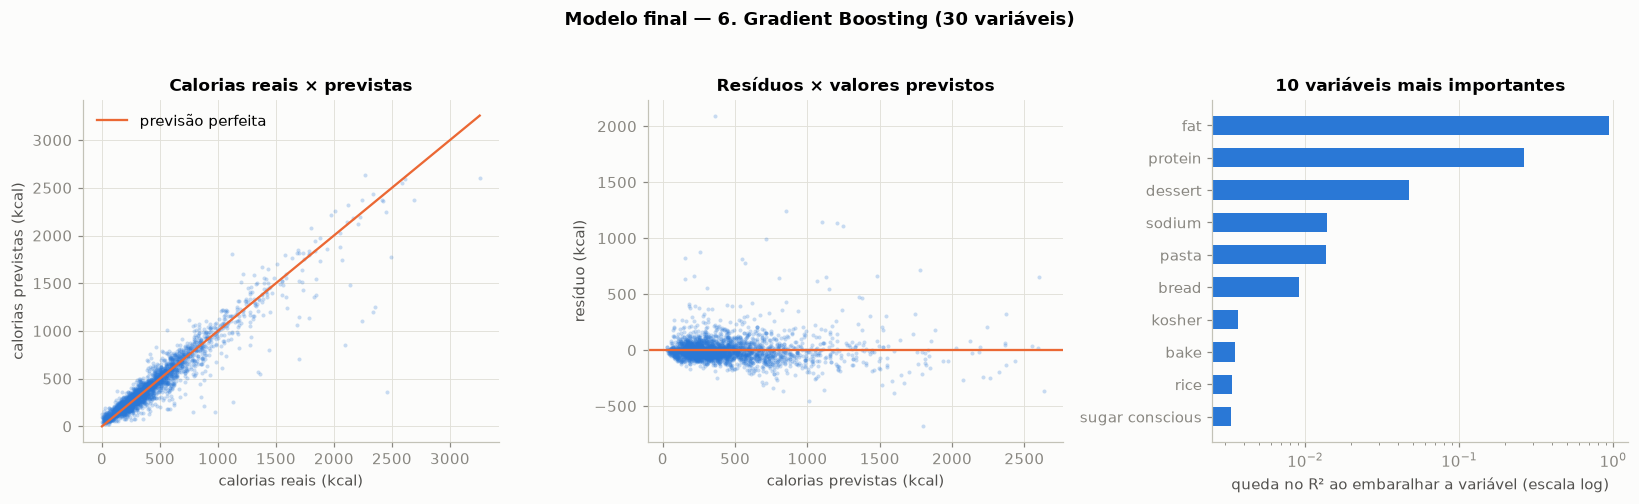

Importância das 10 principais variáveis (queda no R² de teste):
fat                0.9433
protein            0.2638
dessert            0.0474
sodium             0.0138
pasta              0.0137
bread              0.0091
kosher             0.0036
bake               0.0035
rice               0.0033
sugar conscious    0.0033


In [32]:
melhor = tabela["R² ajustado teste"].idxmax()
modelo_final = modelos[melhor]
colunas_finais = variaveis_usadas[melhor]
r = tabela.loc[melhor]
pred = previsoes[melhor]
hiper = {k: modelo_final.get_params()[k] for k in ["loss", "learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "random_state"]}

print("=" * 100)
print(f"MODELO FINAL: {melhor}")
print("=" * 100)
print(f"Algoritmo:               {type(modelo_final).__name__} (scikit-learn)")
print(f"Variável-alvo:           {ALVO} (kcal)")
print(f"Hiperparâmetros:         {hiper}")
print(f"Dados:                   {len(y_treino):,} receitas de treino | {len(y_teste):,} de teste")
print(f"\nVariáveis ({len(colunas_finais)}):")
print(textwrap.fill(", ".join(colunas_finais), width=100, initial_indent="  ", subsequent_indent="  "))
print("\nDesempenho:")
print(f"  R² treino:             {r['R² treino']:.3f}")
print(f"  R² validação cruzada:  {r['R² CV (média)']:.3f} ± {r['R² CV (desvio)']:.3f}")
print(f"  R² teste:              {r['R² teste']:.3f}")
print(f"  R² ajustado teste:     {r['R² ajustado teste']:.3f}")
print(f"  RMSE teste:            {r['RMSE teste']:.0f} kcal")
print(f"  MAE teste:             {r['MAE teste']:.0f} kcal")

perm = permutation_importance(modelo_final, X_teste[colunas_finais], y_teste, n_repeats=10, random_state=SEED, scoring="r2")
imp = pd.Series(perm.importances_mean, index=colunas_finais).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

axes[0].scatter(y_teste, pred, s=7, alpha=0.25, color=AZUL, linewidths=0)
lim = [0, y_teste.max()]
axes[0].plot(lim, lim, color=LARANJA, linewidth=1.5, label="previsão perfeita")
axes[0].set(title="Calorias reais × previstas", xlabel="calorias reais (kcal)", ylabel="calorias previstas (kcal)")
axes[0].legend(frameon=False)

axes[1].scatter(pred, y_teste - pred, s=7, alpha=0.25, color=AZUL, linewidths=0)
axes[1].axhline(0, color=LARANJA, linewidth=1.5)
axes[1].set(title="Resíduos × valores previstos", xlabel="calorias previstas (kcal)", ylabel="resíduo (kcal)")

top = imp.head(10)[::-1]
axes[2].barh(top.index, top.values, color=AZUL, height=0.6)
axes[2].set_xscale("log")
axes[2].set(title="10 variáveis mais importantes", xlabel="queda no R² ao embaralhar a variável (escala log)")
axes[2].grid(axis="y", visible=False)

fig.suptitle(f"Modelo final — {melhor}", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

print("Importância das 10 principais variáveis (queda no R² de teste):")
print(imp.head(10).round(4).to_string())

## 12. O modelo na prática

Para ver o modelo funcionando, a célula abaixo sorteia **uma receita do conjunto de teste** (que o modelo nunca
viu no treino), faz a previsão e compara com o valor real. Cada execução sorteia uma receita diferente.

In [33]:
# Sorteia uma receita do conjunto de teste (sem semente: muda a cada execução)
i = np.random.default_rng().choice(X_teste.index)
receita = dados.loc[i]

real = y_teste.loc[i]
previsto = modelo_final.predict(X_teste.loc[[i], colunas_finais])[0]
erro = previsto - real

tags_no_modelo = [c for c in colunas_finais if c not in MACROS and receita[c] == 1]

print(f"Receita:            {receita['title'].strip()}")
print(f"Gordura:            {receita['fat']:.0f} g")
print(f"Proteína:           {receita['protein']:.0f} g")
print(f"Sódio:              {receita['sodium']:.0f} mg")
print(f"Tags do modelo:     {', '.join(tags_no_modelo) if tags_no_modelo else 'nenhuma'}")
print("-" * 60)
print(f"Calorias reais:     {real:.0f} kcal")
print(f"Calorias previstas: {previsto:.0f} kcal")
print(f"Erro:               {erro:+.0f} kcal ({abs(erro) / real:.1%} do valor real)" if real > 0 else f"Erro:               {erro:+.0f} kcal")
print(f"\nPara comparação, o erro absoluto médio do modelo no teste é de {tabela.loc[melhor, 'MAE teste']:.0f} kcal.")

Receita:            Curried Pumpkin Breads
Gordura:            23 g
Proteína:           17 g
Sódio:              1525 mg
Tags do modelo:     bake, bread
------------------------------------------------------------
Calorias reais:     701 kcal
Calorias previstas: 657 kcal
Erro:               -44 kcal (6.3% do valor real)

Para comparação, o erro absoluto médio do modelo no teste é de 66 kcal.
